# TP M2-2 — Vos données phyphox : détecter les pas et les chutes

**Module 2 — vendredi 9 octobre 2026 — 14:00-14:45 (en équipe)**
MBA Santé, IA & IoT — Epitech — Nicolas LAURIO — **Équipe 05**

> Données : enregistrements phyphox de l'accéléromètre (module 1), pseudonymisés. Si aucun fichier d'équipe bien nommé n'est trouvé, le notebook passe sur un **jeu de secours synthétique** (11 enregistrements fabriqués par programme, équipe fictive `eq00` : personne n'a été enregistré). Usage **pédagogique** uniquement, aucun diagnostic.

Plan : 1. charger → 2. contrôler la qualité → 3. compter les pas → 4. détecter une « chute » (règle naïve vs règle à trois temps) → 5. livrable `analyses/m2_tp2/`.

## Étape 1 — Ouvrir le notebook et charger les données

✏️ **À vous** : écrivez votre numéro d'équipe. Laissez `FORCER_SECOURS = False` sauf si vous êtes bloqués.

In [1]:
#@title À vous : numéro d'équipe
EQUIPE = "eq05"  #@param {type:"string"}
FORCER_SECOURS = False  #@param {type:"boolean"}
# FORCER_SECOURS = True : prendre le jeu de secours synthétique même si vos fichiers sont là

▶ **Boîte à outils : exécutez la cellule suivante sans la modifier.** Elle contient le lecteur de fichiers phyphox, le contrôle qualité, le compteur de pas, les deux règles de chute et le générateur du jeu de secours.

In [2]:
# ===== Boîte à outils : exécutez cette cellule sans la modifier =====
import io
import re
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal
from scipy.spatial.transform import Rotation, Slerp

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

G = 9.80665  # 1 g en m/s²
MOTIF_NOM = re.compile(
    r"^(?P<date>\d{8})_(?P<equipe>eq\d{2})_(?P<sujet>s\d{2})_(?P<activite>[a-z\-]+)_(?P<position>[a-z\-]+)_(?P<rep>r\d{2})\.csv$"
)


def afficher(df):
    """Affiche un tableau (display() dans Jupyter/Colab, print() sinon)."""
    try:
        display(df)  # noqa: F821
    except NameError:
        print(df.to_string())


# ---------- Où sont les fichiers ? ----------
def trouver_racine():
    """Racine du repo : le premier dossier parent qui contient .git ou data/ (sinon le dossier courant)."""
    ici = Path.cwd().resolve()
    for d in [ici, *ici.parents]:
        if (d / ".git").exists() or (d / "data" / "raw" / "phyphox").exists():
            return d
    return ici


RACINE = trouver_racine()
DOSSIERS_CANDIDATS = [RACINE / "data" / "raw" / "phyphox", RACINE, Path("/content")]
DOSSIER_EXEMPLE = RACINE / "donnees_M2" / "phyphox_exemple"
SORTIE = RACINE / "analyses" / "m2_tp2"


# ---------- Lecteur « tous formats » ----------
def lire_phyphox(source):
    """Lit un CSV phyphox (séparateur , ; ou tabulation, décimale . ou ,, unité m/s² ou g).
    Renvoie t (s), acc (N x 3, en g) et des infos sur le format."""
    texte = source.read_text(encoding="utf-8-sig") if isinstance(source, Path) else source
    entete = texte.splitlines()[0]
    sep = max([",", ";", "\t"], key=entete.count)
    decimal = "," if sep != "," and re.search(r"\d,\d", texte[:2000]) else "."
    df = pd.read_csv(io.StringIO(texte), sep=sep, decimal=decimal)
    df.columns = [c.strip().strip('"') for c in df.columns]
    col_t = next(c for c in df.columns if re.search(r"time|temps", c, re.I))
    cols = []
    for axe in "xyz":
        cols.append(next(c for c in df.columns
                         if re.search(rf"(acc\w*\s*{axe}\b|\b{axe}\b|^a{axe}$|_{axe}\b|{axe}\s*\()", c, re.I) and c != col_t))
    t = df[col_t].to_numpy(float)
    acc = df[cols].to_numpy(float)
    unite = "m/s²" if any("m/s" in c for c in cols) else ("g" if np.median(np.linalg.norm(acc, axis=1)) < 3 else "m/s²")
    if unite == "m/s²":
        acc = acc / G
    ok = np.isfinite(t) & np.isfinite(acc).all(axis=1)
    return t[ok] - t[ok][0], acc[ok], {"sep": sep, "decimal": decimal, "unite": unite}


def reechantillonner(t, acc):
    """Remet les mesures à intervalles égaux, à la fréquence typique du fichier (médiane des écarts)."""
    dt = np.diff(t)
    fs = float(np.round(1.0 / np.median(dt)))
    t_u = np.arange(0.0, t[-1], 1.0 / fs)
    acc_u = np.column_stack([np.interp(t_u, t, acc[:, k]) for k in range(3)])
    return t_u, acc_u, fs


# ---------- Jeu de secours synthétique (équipe fictive eq00) ----------
def _bosse(t, t0, amp, largeur):
    return amp * np.exp(-0.5 * ((t - t0) / largeur) ** 2)


def _orientation(t, etapes):
    """etapes = [(instant, rotation scipy), ...] -> rotations interpolées (Slerp) à chaque instant."""
    instants = np.array([e[0] for e in etapes], float)
    rots = Rotation.concatenate([e[1] for e in etapes])
    return Slerp(instants, rots)(np.clip(t, instants[0], instants[-1]))


def _scenario(activite, variante, rng):
    """Force spécifique dans le repère du monde (en g, au repos = [0, 0, 1]) sur une grille fine à 1 kHz,
    et l'orientation du téléphone au cours du temps. Renvoie (t, f_monde, orientations, nb_pas_reels)."""
    R = Rotation.from_euler
    duree = {"debout": 20, "marche": 33, "assis-debout": 36, "assis": 20, "allonger": 25, "chute-objet": 11}[activite]
    t = np.arange(0, duree, 0.001)
    f = np.zeros((len(t), 3))
    f[:, 2] = 1.0
    lisse = lambda x, s: np.convolve(x, np.ones(s) / s, mode="same")
    tremblement = lambda amp: np.column_stack([lisse(rng.normal(0, amp, len(t)), 120) for _ in range(3)])
    pas = 0
    hanche = R("xyz", [rng.uniform(-15, 15), 80 + rng.uniform(-5, 5), rng.uniform(0, 360)], degrees=True)
    if activite == "debout":
        f += tremblement(0.06)
        rot = _orientation(t, [(0, hanche), (duree, hanche)])
    elif activite == "assis":
        f += tremblement(0.03)
        f[:, 2] += 0.004 * np.sin(2 * np.pi * 0.25 * t)
        cuisse = R("xyz", [10, 15, 30], degrees=True)
        rot = _orientation(t, [(0, cuisse), (duree, cuisse)])
    elif activite == "marche":
        cadence = 1.80 if variante == 1 else 1.74
        pas = 50 if variante == 1 else 48
        t_pas = 2.0 + np.cumsum(rng.normal(1 / cadence, 0.015, pas)) - 1 / cadence
        for k, tk in enumerate(t_pas):
            # téléphone dans UNE poche : le pas du côté du téléphone secoue plus que celui de l'autre jambe
            amp = (0.42 if k % 2 == 0 else 0.30) * rng.uniform(0.9, 1.1)
            f[:, 2] += _bosse(t, tk, amp, 0.07) - _bosse(t, tk + 0.24, 0.45 * amp, 0.09)
            f[:, 0] += (-1) ** k * _bosse(t, tk + 0.1, 0.12, 0.12)       # balancement latéral
            f[:, 1] += _bosse(t, tk - 0.05, 0.15, 0.06) - _bosse(t, tk + 0.12, 0.10, 0.08)
        f += tremblement(0.25)
        rot = _orientation(t, [(0, hanche), (duree, hanche * R("x", 8, degrees=True))])
    elif activite == "assis-debout":
        assis = hanche * R("y", -70, degrees=True)
        etapes, lourd = [(0, hanche)], variante == 2
        for k, (t_assis, t_debout) in enumerate([(4, 12), (18, 26)]):
            if lourd and k == 1:
                # « s'asseoir lourdement » : on se laisse tomber sur la chaise (creux à ~0,5 g), puis choc
                f[:, 2] += -_bosse(t, t_assis + 0.55, 0.50, 0.10) + _bosse(t, t_assis + 0.80, 1.9, 0.025)
            else:
                f[:, 2] += -_bosse(t, t_assis + 0.4, 0.15, 0.25) + _bosse(t, t_assis + 1.0, 0.30, 0.20)
            f[:, 2] += _bosse(t, t_debout + 0.5, 0.30, 0.25) - _bosse(t, t_debout + 1.2, 0.18, 0.25)
            f[:, 1] += _bosse(t, t_assis + 0.7, 0.20, 0.30) - _bosse(t, t_debout + 0.6, 0.20, 0.30)
            etapes += [(t_assis, hanche), (t_assis + 1.2, assis), (t_debout, assis), (t_debout + 1.2, hanche)]
        etapes.append((duree, hanche))
        f += tremblement(0.04)
        rot = _orientation(t, etapes)
    elif activite == "allonger":
        couche = hanche * R("x", 90, degrees=True)
        f[:, 2] += _bosse(t, 5.6, 0.35, 0.25) - _bosse(t, 6.5, 0.25, 0.3) + _bosse(t, 7.8, 0.45, 0.2)
        f[:, 0] += _bosse(t, 7.2, 0.30, 0.3)
        f += tremblement(0.04)
        rot = _orientation(t, [(0, hanche), (5, hanche), (8.5, couche), (duree, couche)])
    elif activite == "chute-objet":
        # Téléphone tenu en main, lâché de 50 cm sur un coussin : chute libre, choc, rebond, immobilité.
        amp, larg = {1: (3.6, 0.020), 2: (9.5, 0.012), 3: (2.8, 0.025)}[variante]
        t0, t_cl = 3.0, np.sqrt(2 * 0.5 / G)            # √(2h/g) ≈ 0,32 s
        t_imp = t0 + t_cl
        en_main = t < t0
        f += tremblement(0.10) * en_main[:, None]
        chute = (t >= t0) & (t < t_imp)
        f[chute] = rng.normal(0, 0.03, (chute.sum(), 3)) + np.array([0.05, 0.03, 0.04])
        apres = t >= t_imp
        f[apres, 2] = 1.0 + _bosse(t[apres], t_imp + larg, amp, larg)
        rebond = (t >= t_imp + 0.09) & (t < t_imp + 0.14)
        f[rebond] = np.array([0.0, 0.05, 0.10])
        f[:, 2] += _bosse(t, t_imp + 0.16, 0.8, 0.015) * apres
        main = R("xyz", [35, -10, 20], degrees=True)
        pose = R("z", rng.uniform(0, 360), degrees=True)
        rot = _orientation(t, [(0, main), (t0, main), (t_imp, pose), (duree, pose)])
    return t, f, rot, pas


SECOURS = [  # (sujet, activité, position, répétition, variante)
    ("s01", "debout", "hanche", 1, 1), ("s01", "marche", "hanche", 1, 1), ("s01", "assis-debout", "hanche", 1, 1),
    ("s01", "assis", "hanche", 1, 1), ("s01", "allonger", "hanche", 1, 1), ("s01", "chute-objet", "main", 1, 1),
    ("s02", "debout", "hanche", 1, 1), ("s02", "marche", "hanche", 1, 2), ("s02", "assis-debout", "hanche", 1, 2),
    ("s02", "chute-objet", "main", 1, 2), ("s02", "chute-objet", "main", 2, 3),
]


def fabriquer_secours(graine=2026):
    """11 CSV au format phyphox « Acceleration (with g) » (m/s²) + labels.csv, en mémoire.
    s01 : ≈ 100 Hz régulier ; s02 : ≈ 200 Hz irrégulier, plage ±8 g (le choc fort sature l'axe z)."""
    rng = np.random.default_rng(graine)
    fichiers, labels = {}, []
    for i, (sujet, act, pos, rep, var) in enumerate(SECOURS):
        t, f, rot, pas = _scenario(act, var, np.random.default_rng(graine + i))
        f_tel = rot.inv().apply(f)                      # repère du téléphone
        if sujet == "s01":
            t_mes = np.arange(0, t[-1], 0.01)
        else:
            t_mes = np.cumsum(rng.uniform(0.0035, 0.0065, int(t[-1] / 0.005) + 50))
            t_mes = t_mes[t_mes < t[-1]]
        acc = np.column_stack([np.interp(t_mes, t, f_tel[:, k]) for k in range(3)])
        acc += rng.normal(0, 0.006, acc.shape)          # bruit du capteur
        if sujet == "s02":
            acc = np.clip(acc, -8, 8)                   # plage de mesure ±8 g
        nom = f"20261002_eq00_{sujet}_{act}_{pos}_r{rep:02d}.csv"
        df = pd.DataFrame({"Time (s)": t_mes, "Acceleration x (m/s^2)": acc[:, 0] * G,
                           "Acceleration y (m/s^2)": acc[:, 1] * G, "Acceleration z (m/s^2)": acc[:, 2] * G})
        fichiers[nom] = df.to_csv(index=False, float_format="%.6f")
        if act == "marche":
            labels.append({"fichier": nom, "etiquette": f"marche-{pas}-pas"})
    return fichiers, pd.DataFrame(labels)


# ---------- Chargement ----------
def charger_donnees(equipe, forcer_secours=False):
    """Renvoie (dict nom -> (t, acc en g, fs, infos), labels, SOURCE, fichiers ignorés)."""
    ignores, trouves = [], {}
    if not forcer_secours:
        for d in DOSSIERS_CANDIDATS:
            if not d.exists():
                continue
            for p in sorted(d.glob("*.csv")):
                if p.name == "labels.csv" or p.name in trouves:
                    continue
                m = MOTIF_NOM.match(p.name)
                if m and m["equipe"] == equipe:
                    trouves[p.name] = p
                elif not m:
                    ignores.append(p.name)
    labels = pd.DataFrame(columns=["fichier", "etiquette"])
    if trouves:
        source = f"fichiers de l'équipe ({len(trouves)} fichiers, dossier {next(iter(trouves.values())).parent})"
        brut = {n: p for n, p in trouves.items()}
        lab = next(iter(trouves.values())).parent / "labels.csv"
        if lab.exists():
            labels = pd.read_csv(lab)
    elif DOSSIER_EXEMPLE.exists() and not forcer_secours:
        brut = {p.name: p for p in sorted(DOSSIER_EXEMPLE.glob("*.csv")) if MOTIF_NOM.match(p.name)}
        source = f"jeu d'exemple SYNTHÉTIQUE ({len(brut)} fichiers, dossier {DOSSIER_EXEMPLE})"
        if (DOSSIER_EXEMPLE / "labels.csv").exists():
            labels = pd.read_csv(DOSSIER_EXEMPLE / "labels.csv")
    else:
        brut, labels = fabriquer_secours()
        source = ("jeu de secours SYNTHÉTIQUE (forcé)" if forcer_secours
                  else "jeu de secours SYNTHÉTIQUE (aucun fichier bien nommé trouvé)")
    donnees = {}
    for nom, src in brut.items():
        t, acc, infos = lire_phyphox(src)
        infos["dt_brut"] = np.diff(t)
        infos["acc_brut"] = acc
        t_u, acc_u, fs = reechantillonner(t, acc)
        donnees[nom] = (t_u, acc_u, fs, infos)
    return donnees, labels, source, ignores


def meta(nom):
    return MOTIF_NOM.match(nom).groupdict()


def norme(acc):
    """‖a‖ = √(ax² + ay² + az²), en g."""
    return np.sqrt((acc ** 2).sum(axis=1))


# ---------- Contrôle qualité ----------
def controle_qualite(nom, t, acc, fs, infos):
    n = norme(acc)
    dt = infos["dt_brut"]
    alertes = []
    if abs(np.median(n) - 1) > 0.10:
        alertes.append("norme au repos ≠ 1 g (unité ? accélération « sans g » ?)")
    if fs < 50:
        alertes.append("fréquence < 50 Hz")
    if dt.max() > 5 * np.median(dt):
        alertes.append(f"trou de {dt.max():.2f} s")
    brut = infos["acc_brut"]
    for k, axe in enumerate("xyz"):
        a = np.abs(brut[:, k])
        haut = a >= a.max() - 1e-6
        if a.max() > 3 and np.convolve(haut, np.ones(3), "valid").max() >= 3:
            alertes.append(f"saturation axe {axe} à {a.max():.1f} g")
    if t[-1] < 5:
        alertes.append("enregistrement < 5 s")
    return {"fichier": nom, "fs_hz": fs, "irregularite_pct": round(100 * dt.std() / dt.mean(), 1),
            "duree_s": round(t[-1], 1), "norme_mediane_g": round(float(np.median(n)), 3),
            "norme_max_g": round(float(n.max()), 2), "alertes_qualite": " ; ".join(alertes) or "-"}


# ---------- Partie 1 : compter les pas ----------
def compter_pas(n, fs, f_bas=0.5, f_haut=3.0, hauteur_g=0.10, distance_s=0.30):
    """norme (g) -> passe-bande Butterworth ordre 2 (filtfilt) -> find_peaks(hauteur, distance) -> cadence."""
    b, a = signal.butter(2, [f_bas, f_haut], btype="bandpass", fs=fs)
    filtre = signal.filtfilt(b, a, n)
    pics, _ = signal.find_peaks(filtre, height=hauteur_g, distance=max(1, int(round(distance_s * fs))))
    cadence = 60.0 / np.median(np.diff(pics) / fs) if len(pics) >= 2 else np.nan
    return {"filtre": filtre, "pics": pics, "nb_pas": len(pics), "cadence": cadence}


# ---------- Partie 2 : deux règles de chute ----------
def regle_naive(n, fs, seuil_g=2.5, refractaire_s=10.0):
    """Firmware du module 1 : alerte dès que ‖a‖ > 2,5 g, au plus une alerte toutes les 10 s."""
    alertes, derniere = [], -np.inf
    for i in np.flatnonzero(n > seuil_g):
        if (i - derniere) / fs >= refractaire_s:
            alertes.append(i)
            derniere = i
    return alertes


def _plages(masque):
    d = np.diff(np.r_[0, masque.astype(int), 0])
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))


def regle_trois_temps(n, fs, seuil_cl_g=0.4, duree_cl_s=0.08, seuil_impact_g=2.0, fenetre_impact_s=1.0,
                      seuil_immobile_g=0.05, debut_immobile_s=1.0, duree_immobile_s=3.0):
    """1. chute libre : ‖a‖ < seuil_cl_g pendant ≥ duree_cl_s ;
    2. impact : pic > seuil_impact_g dans la seconde qui suit ;
    3. immobilité : écart-type de ‖a‖ < seuil_immobile_g de debut_immobile_s à debut+duree après le choc.
    Renvoie la liste des événements (dict avec les indices de chaque phase)."""
    evenements = []
    for deb, fin in _plages(n < seuil_cl_g):
        if (fin - deb) / fs < duree_cl_s:
            continue
        fen = n[fin: fin + int(fenetre_impact_s * fs)]
        if len(fen) == 0 or fen.max() <= seuil_impact_g:
            continue
        i_imp = fin + int(np.argmax(fen))
        i0, i1 = i_imp + int(debut_immobile_s * fs), i_imp + int((debut_immobile_s + duree_immobile_s) * fs)
        if i1 > len(n) or n[i0:i1].std() >= seuil_immobile_g:
            continue
        if evenements and (i_imp - evenements[-1]["impact"]) / fs < 2.0:
            continue
        evenements.append({"chute_libre": (deb, fin), "impact": i_imp, "immobile": (i0, i1)})
    return evenements


def classer(verite, alerte):
    return {(True, True): "VP", (True, False): "FN", (False, True): "FP", (False, False): "VN"}[(verite, alerte)]


def matrice(resultats):
    c = pd.Series(resultats).value_counts()
    vp, fn, fp, vn = (int(c.get(k, 0)) for k in ("VP", "FN", "FP", "VN"))
    m = pd.DataFrame([[vp, fn], [fp, vn]], index=["chute réelle", "pas de chute"], columns=["alerte", "pas d'alerte"])
    precision = vp / (vp + fp) if vp + fp else float("nan")
    rappel = vp / (vp + fn) if vp + fn else float("nan")
    return m, vp, fn, fp, vn, precision, rappel


print("Boîte à outils prête — équipe", EQUIPE, "— racine du repo :", RACINE)

Boîte à outils prête — équipe eq05 — racine du repo : /home/claude/usannazcedric/monitoring-ehpad


▶ **Exécutez** : chargement des fichiers. Lisez la ligne **Source : …**.

In [3]:
DONNEES, LABELS, SOURCE, IGNORES = charger_donnees(EQUIPE, FORCER_SECOURS)
print("Source :", SOURCE)
print(f"{len(DONNEES)} fichiers chargés")
if IGNORES:
    print("⚠ Fichiers CSV ignorés (nom hors convention AAAAMMJJ_eqNN_sNN_<activite>_<position>_rNN.csv) :", IGNORES)
for nom in DONNEES:
    print("  -", nom)

Source : jeu de secours SYNTHÉTIQUE (aucun fichier bien nommé trouvé)
11 fichiers chargés
  - 20261002_eq00_s01_debout_hanche_r01.csv
  - 20261002_eq00_s01_marche_hanche_r01.csv
  - 20261002_eq00_s01_assis-debout_hanche_r01.csv
  - 20261002_eq00_s01_assis_hanche_r01.csv
  - 20261002_eq00_s01_allonger_hanche_r01.csv
  - 20261002_eq00_s01_chute-objet_main_r01.csv
  - 20261002_eq00_s02_debout_hanche_r01.csv
  - 20261002_eq00_s02_marche_hanche_r01.csv
  - 20261002_eq00_s02_assis-debout_hanche_r01.csv
  - 20261002_eq00_s02_chute-objet_main_r01.csv
  - 20261002_eq00_s02_chute-objet_main_r02.csv


## Étape 2 — Contrôler la qualité

Une ligne par fichier : `fs_hz` (mesures par seconde, après remise à intervalles égaux), `irregularite_pct` (variation des écarts entre deux mesures dans le fichier brut), `norme_mediane_g` (valeur typique, attendue ≈ 1 g), `norme_max_g`, `alertes_qualite` (« - » = aucun problème).

In [4]:
QUALITE = pd.DataFrame([controle_qualite(nom, *DONNEES[nom]) for nom in DONNEES])
afficher(QUALITE)

                                          fichier  fs_hz  irregularite_pct  duree_s  norme_mediane_g  norme_max_g           alertes_qualite
0         20261002_eq00_s01_debout_hanche_r01.csv  100.0               0.0     20.0            1.000         1.03                         -
1         20261002_eq00_s01_marche_hanche_r01.csv  100.0               0.0     33.0            1.003         1.48                         -
2   20261002_eq00_s01_assis-debout_hanche_r01.csv  100.0               0.0     36.0            1.000         1.32                         -
3          20261002_eq00_s01_assis_hanche_r01.csv  100.0               0.0     20.0            1.000         1.03                         -
4       20261002_eq00_s01_allonger_hanche_r01.csv  100.0               0.0     25.0            1.001         1.46                         -
5      20261002_eq00_s01_chute-objet_main_r01.csv  100.0               0.0     11.0            1.000         4.59                         -
6         20261002_e

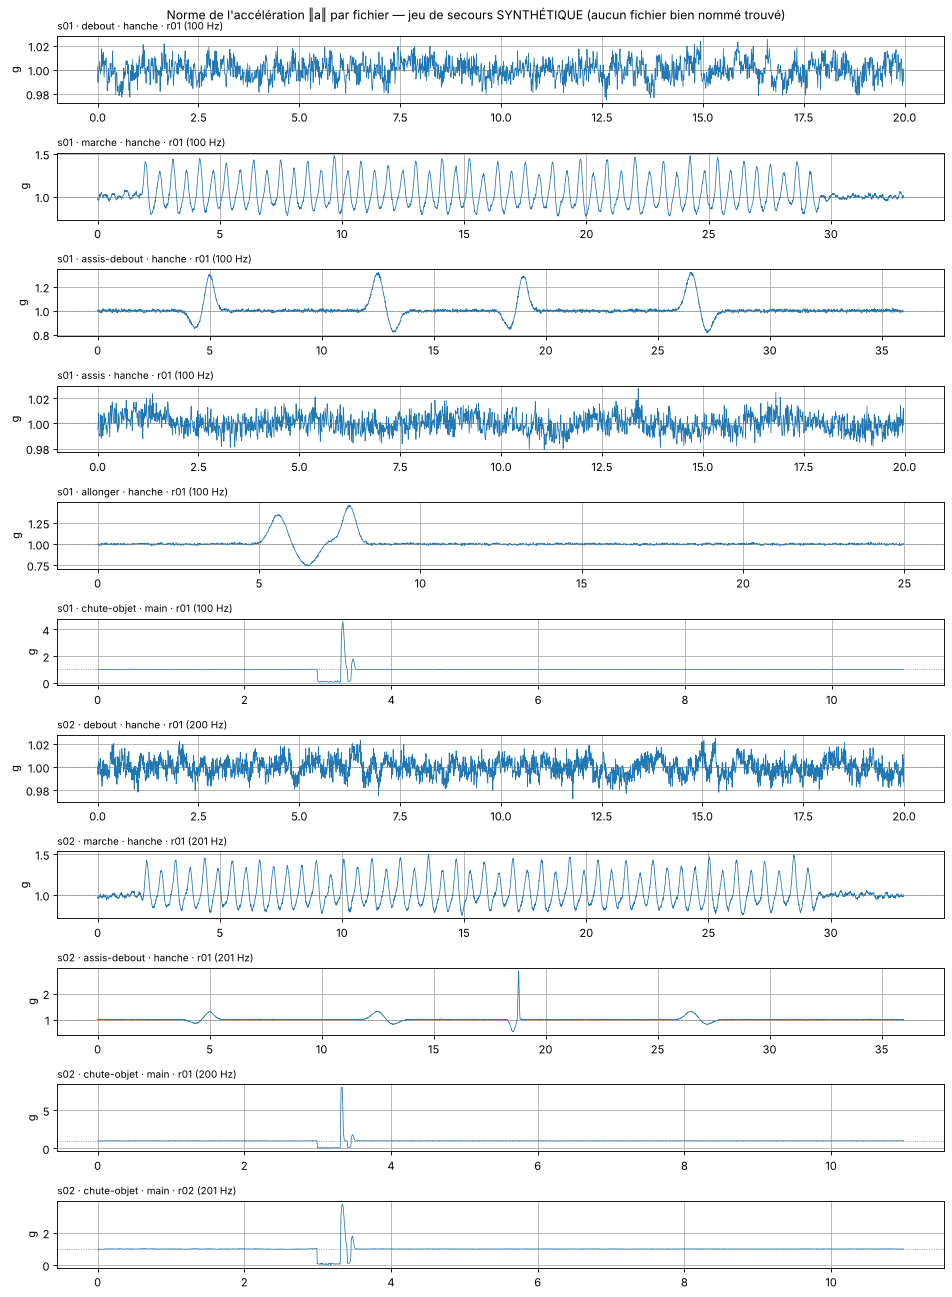

In [5]:
# Vue d'ensemble : une courbe de norme par fichier
fig, axes = plt.subplots(len(DONNEES), 1, figsize=(12, 1.5 * len(DONNEES)), sharex=False)
for ax, (nom, (t, acc, fs, infos)) in zip(axes, DONNEES.items()):
    m = meta(nom)
    ax.plot(t, norme(acc), lw=0.7)
    ax.axhline(1, color="grey", ls=":", lw=0.8)
    ax.set_ylabel("g")
    ax.set_title(f"{m['sujet']} · {m['activite']} · {m['position']} · {m['rep']} ({fs:.0f} Hz)", fontsize=9, loc="left")
fig.suptitle(f"Norme de l'accélération ‖a‖ par fichier — {SOURCE}", fontsize=11)
fig.tight_layout()
FIG_APERCU = fig
plt.show()

**Q1.** Combien de mesures par seconde font vos téléphones (colonne `fs_hz`) ? Est-ce pareil pour tous les membres de l'équipe ? En une phrase : pourquoi le notebook remet-il les mesures à intervalles égaux ?

*Vos réponses :*

⚠ **Résultats obtenus sur le jeu de secours SYNTHÉTIQUE** (équipe fictive `eq00`) : aucun fichier phyphox de l'équipe 05 n'est présent dans `data/raw/phyphox/` du repo.

Le téléphone **s01** fait **100 mesures par seconde**, de façon régulière (irrégularité 0 %). Le téléphone **s02** en fait **≈ 200** (200 ou 201 Hz selon le fichier), et de façon **irrégulière** : l'écart entre deux mesures varie d'environ 17 %. Ce n'est donc **pas pareil** d'un membre à l'autre : la fréquence dépend du modèle de téléphone et de sa charge.

Le notebook remet les mesures à intervalles égaux parce que le filtre passe-bande et `find_peaks` supposent un écart **fixe** entre deux mesures (c'est ce qui permet de convertir des numéros de mesure en secondes et en Hz) : avec des écarts irréguliers, la fréquence de coupure et la distance minimale entre pas seraient fausses.

## Étape 3 — Partie 1 : compter les pas

`compter_pas()` : norme (g) → passe-bande 0,5-3 Hz (Butterworth, ordre 2) → `find_peaks(hauteur, distance)` → cadence.

✏️ **À vous** : réglages du compteur, et nombre de pas réel si absent de `labels.csv` (format `{"nom_du_fichier.csv": nombre}`).

In [6]:
#@title ✏️ À vous : réglages du compteur de pas
f_bas = 0.5       # Hz
f_haut = 3.0      # Hz
hauteur_g = 0.10  # Q3 : passez à 0.3, relancez cette cellule et celle du tableau, puis remettez 0.10
distance_s = 0.30

PAS_REELS = {}    # ex. {"20261002_eq05_s01_marche_hanche_r01.csv": 52}

# nombres de pas lus dans labels.csv (étiquettes « marche-NN-pas »)
for _, ligne in LABELS.iterrows():
    m = re.match(r"marche-(\d+)-pas", str(ligne["etiquette"]))
    if m:
        PAS_REELS.setdefault(ligne["fichier"], int(m.group(1)))
MARCHES = [nom for nom in DONNEES if meta(nom)["activite"] == "marche"]
FICHIER_MARCHE = MARCHES[0]
print("Pas réels connus :", PAS_REELS)

Pas réels connus : {'20261002_eq00_s01_marche_hanche_r01.csv': 50, '20261002_eq00_s02_marche_hanche_r01.csv': 48}


In [7]:
def table_pas(**reglages):
    lignes = []
    for nom, (t, acc, fs, infos) in DONNEES.items():
        m = meta(nom)
        r = compter_pas(norme(acc), fs, **reglages)
        reel = PAS_REELS.get(nom, 0 if m["activite"] != "marche" else np.nan)
        ecart = 100 * (r["nb_pas"] - reel) / reel if reel else np.nan
        lignes.append({"fichier": nom, "sujet": m["sujet"], "activite": m["activite"], "position": m["position"],
                       "pas_detectes": r["nb_pas"], "pas_reels": reel,
                       "ecart_pct": round(ecart, 1) if np.isfinite(ecart) else np.nan,
                       "cadence_pas_min": round(r["cadence"], 1) if np.isfinite(r["cadence"]) else np.nan})
    return pd.DataFrame(lignes)


REGLAGES_PAS = dict(f_bas=f_bas, f_haut=f_haut, hauteur_g=hauteur_g, distance_s=distance_s)
TABLE_PAS = table_pas(**REGLAGES_PAS)
print("Réglages :", REGLAGES_PAS)
afficher(TABLE_PAS)

Réglages : {'f_bas': 0.5, 'f_haut': 3.0, 'hauteur_g': 0.1, 'distance_s': 0.3}
                                          fichier sujet      activite position  pas_detectes  pas_reels  ecart_pct  cadence_pas_min
0         20261002_eq00_s01_debout_hanche_r01.csv   s01        debout   hanche             0          0        NaN              NaN
1         20261002_eq00_s01_marche_hanche_r01.csv   s01        marche   hanche            50         50        0.0            109.1
2   20261002_eq00_s01_assis-debout_hanche_r01.csv   s01  assis-debout   hanche             4          0        NaN              8.0
3          20261002_eq00_s01_assis_hanche_r01.csv   s01         assis   hanche             0          0        NaN              NaN
4       20261002_eq00_s01_allonger_hanche_r01.csv   s01      allonger   hanche             2          0        NaN             27.5
5      20261002_eq00_s01_chute-objet_main_r01.csv   s01   chute-objet     main             2          0        NaN            117.

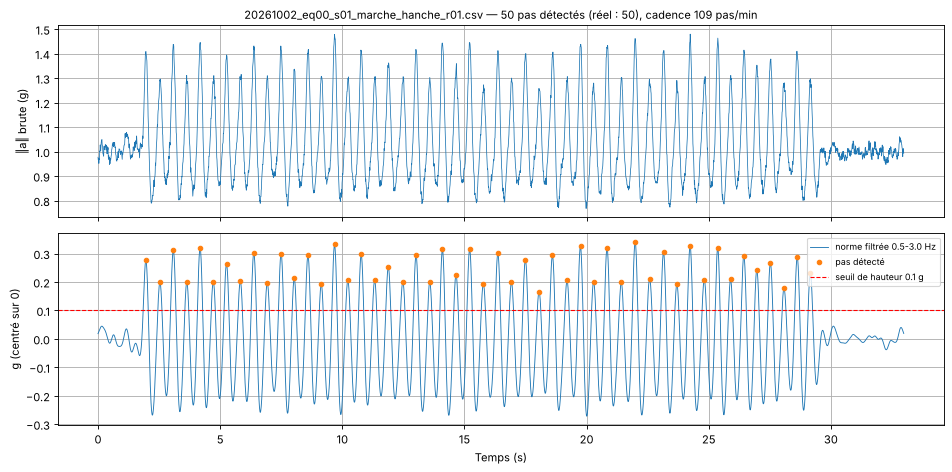

In [8]:
# Figure : norme brute (haut) et norme filtrée avec les pas détectés (bas)
t, acc, fs, _ = DONNEES[FICHIER_MARCHE]
n = norme(acc)
r = compter_pas(n, fs, **REGLAGES_PAS)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(t, n, lw=0.7)
ax1.set_ylabel("‖a‖ brute (g)")
ax1.set_title(f"{FICHIER_MARCHE} — {r['nb_pas']} pas détectés (réel : {PAS_REELS.get(FICHIER_MARCHE, '?')}), "
              f"cadence {r['cadence']:.0f} pas/min", fontsize=10)
ax2.plot(t, r["filtre"], lw=0.8, label=f"norme filtrée {f_bas}-{f_haut} Hz")
ax2.plot(t[r["pics"]], r["filtre"][r["pics"]], "o", color="tab:orange", ms=4, label="pas détecté")
ax2.axhline(hauteur_g, color="red", ls="--", lw=1, label=f"seuil de hauteur {hauteur_g} g")
ax2.set_xlabel("Temps (s)")
ax2.set_ylabel("g (centré sur 0)")
ax2.legend(loc="upper right", fontsize=8)
fig.tight_layout()
FIG_PAS = fig
plt.show()

In [9]:
# Q3 — même tableau avec hauteur_g = 0.3 (comparaison, les réglages par défaut restent en place)
comparaison = TABLE_PAS[["fichier", "activite", "pas_reels"]].copy()
comparaison["pas_h0.10"] = TABLE_PAS["pas_detectes"]
comparaison["pas_h0.30"] = table_pas(f_bas=f_bas, f_haut=f_haut, hauteur_g=0.3, distance_s=distance_s)["pas_detectes"]
r_marche = [compter_pas(norme(DONNEES[nm][1]), DONNEES[nm][2], **REGLAGES_PAS) for nm in MARCHES]
comparaison_hauteurs = [float(np.median(rm["filtre"][rm["pics"]])) for rm in r_marche]
afficher(comparaison)
for nm, h in zip(MARCHES, comparaison_hauteurs):
    print(f"Hauteur médiane des pics de pas (filtré) sur {nm} : {h:.2f} g")

                                          fichier      activite  pas_reels  pas_h0.10  pas_h0.30
0         20261002_eq00_s01_debout_hanche_r01.csv        debout          0          0          0
1         20261002_eq00_s01_marche_hanche_r01.csv        marche         50         50         14
2   20261002_eq00_s01_assis-debout_hanche_r01.csv  assis-debout          0          4          0
3          20261002_eq00_s01_assis_hanche_r01.csv         assis          0          0          0
4       20261002_eq00_s01_allonger_hanche_r01.csv      allonger          0          2          0
5      20261002_eq00_s01_chute-objet_main_r01.csv   chute-objet          0          2          1
6         20261002_eq00_s02_debout_hanche_r01.csv        debout          0          0          0
7         20261002_eq00_s02_marche_hanche_r01.csv        marche         48         48         17
8   20261002_eq00_s02_assis-debout_hanche_r01.csv  assis-debout          0          4          1
9      20261002_eq00_s02_chute

**Q2.** Dans `TABLE_PAS`, lisez pour vos fichiers de marche : pas comptés, pas réels, cadence. Le compte est-il juste ? La cadence est-elle normale (adulte : environ 100 à 120 pas/min) ?

*Vos réponses :*

| Fichier de marche | Pas comptés | Pas réels | Écart | Cadence |
|---|---|---|---|---|
| s01 marche hanche r01 | 50 | 50 | 0 % | 109 pas/min |
| s02 marche hanche r01 | 48 | 48 | 0 % | 104 pas/min |

Le compte est **juste** sur les deux fichiers, et les cadences (104-109 pas/min) sont **normales** pour une marche d'adulte (100-120 pas/min).

Limite : ce sont des données synthétiques, propres et régulières ; sur de vrais enregistrements, on s'attend à quelques pas manqués ou en trop, surtout au départ et à l'arrêt de la marche.

**Q3.** Passez `hauteur_g` à 0.3 : on exige des pics plus hauts. Combien de pas le programme compte-t-il maintenant ? Pourquoi, en une phrase ?

*Vos réponses :*

Avec `hauteur_g = 0.3`, le programme ne compte plus que **14 pas sur 50** (s01) et **17 sur 48** (s02). Une fois filtrés, les pics de pas font typiquement 0,2 à 0,3 g (médiane 0,25 g) : le téléphone est dans **une seule** poche, donc les pas de la jambe opposée secouent moins (≈ 0,20 g, tous sous le seuil) et seule une partie des pas du « bon » côté dépasse 0,3 g. Un seuil trop haut fait rater de vrais pas ; on remet 0,10 g.

**Q4.** Combien de « pas » le programme compte-t-il sur les fichiers où personne ne marche (assis-debout, s'allonger, chute) ? En une phrase : comment un podomètre du commerce pourrait-il éviter ça ?

*Vos réponses :*

Sur les fichiers où personne ne marche, le programme compte des pas parasites : **4** sur chaque fichier assis-debout (un par passage assis ↔ debout), **2** sur s'allonger, **2** sur chaque chute d'objet (le choc et le rebond). Il en compte **0** sur debout et assis, immobiles. Soit **16 faux pas** au total.

Un podomètre du commerce les évite en ne validant les pas que **par séries** : il attend plusieurs pas réguliers d'affilée (par exemple 4 à 10 pas avec des intervalles proches) avant de commencer à compter, ce qu'un mouvement isolé ne produit jamais.

## Étape 4 — Partie 2 : détecter une « chute »

- **(a) Règle naïve** (firmware du module 1) : alerte dès que ‖a‖ > 2,5 g (`FALL_THRESHOLD_G = 2.5`), au plus une alerte toutes les 10 s.
- **(b) Règle à trois temps** : chute libre (‖a‖ < 0,4 g pendant ≥ 80 ms) → impact (pic > 2 g dans la seconde qui suit) → immobilité (écart-type de ‖a‖ < 0,05 g de 1 à 4 s après le choc).

Seule l'activité `chute-objet` est une vraie chute.

In [10]:
#@title ✏️ À vous : réglages de la règle à trois temps
REGLAGES_3T = dict(seuil_cl_g=0.4, duree_cl_s=0.08, seuil_impact_g=2.0, fenetre_impact_s=1.0,
                   seuil_immobile_g=0.05, debut_immobile_s=1.0, duree_immobile_s=3.0)
# REGLAGES_3T.update(seuil_cl_g=0.6, duree_immobile_s=2.0)   # Q6 : réglage « tolérant » (enlevez le #, relancez la suite, remettez le #)
FALL_THRESHOLD_G = 2.5
print("Règle à trois temps :", REGLAGES_3T)

Règle à trois temps : {'seuil_cl_g': 0.4, 'duree_cl_s': 0.08, 'seuil_impact_g': 2.0, 'fenetre_impact_s': 1.0, 'seuil_immobile_g': 0.05, 'debut_immobile_s': 1.0, 'duree_immobile_s': 3.0}


In [11]:
def table_chute(reglages_3t):
    lignes = []
    for nom, (t, acc, fs, infos) in DONNEES.items():
        m = meta(nom)
        n = norme(acc)
        verite = m["activite"] == "chute-objet"
        naive = regle_naive(n, fs, FALL_THRESHOLD_G)
        trois = regle_trois_temps(n, fs, **reglages_3t)
        lignes.append({"fichier": nom, "sujet": m["sujet"], "activite": m["activite"], "verite_chute": verite,
                       "norme_min_g": round(float(n.min()), 2), "norme_max_g": round(float(n.max()), 2),
                       "alertes_naive": len(naive), "alerte_naive": bool(naive),
                       "resultat_naive": classer(verite, bool(naive)),
                       "alertes_trois_temps": len(trois), "alerte_trois_temps": bool(trois),
                       "resultat_trois_temps": classer(verite, bool(trois))})
    return pd.DataFrame(lignes)


TABLE_CHUTE = table_chute(REGLAGES_3T)
afficher(TABLE_CHUTE[["fichier", "verite_chute", "norme_min_g", "norme_max_g", "alertes_naive", "resultat_naive",
                      "alertes_trois_temps", "resultat_trois_temps"]])

                                          fichier  verite_chute  norme_min_g  norme_max_g  alertes_naive resultat_naive  alertes_trois_temps resultat_trois_temps
0         20261002_eq00_s01_debout_hanche_r01.csv         False         0.97         1.03              0             VN                    0                   VN
1         20261002_eq00_s01_marche_hanche_r01.csv         False         0.77         1.48              0             VN                    0                   VN
2   20261002_eq00_s01_assis-debout_hanche_r01.csv         False         0.81         1.32              0             VN                    0                   VN
3          20261002_eq00_s01_assis_hanche_r01.csv         False         0.98         1.03              0             VN                    0                   VN
4       20261002_eq00_s01_allonger_hanche_r01.csv         False         0.74         1.46              0             VN                    0                   VN
5      20261002_eq00_s01_chu

In [12]:
SCORES = {}
for regle, col in [("Règle naïve (> 2,5 g)", "resultat_naive"), ("Règle à trois temps", "resultat_trois_temps")]:
    m, vp, fn, fp, vn, p, r = matrice(TABLE_CHUTE[col])
    SCORES[regle] = {"VP": vp, "FN": fn, "FP": fp, "VN": vn, "precision": p, "rappel": r}
    print(f"\n=== {regle} ===")
    print(m.to_string())
    print(f"En mots : {vp} bonne(s) alerte(s), {fn} chute(s) ratée(s), {fp} fausse(s) alerte(s), {vn} calme(s) à raison.")
    print(f"Précision = VP/(VP+FP) = {vp}/{vp + fp} = {p:.2f}   |   Rappel = VP/(VP+FN) = {vp}/{vp + fn} = {r:.2f}")
SCORES = pd.DataFrame(SCORES).T


=== Règle naïve (> 2,5 g) ===
              alerte  pas d'alerte
chute réelle       3             0
pas de chute       1             7
En mots : 3 bonne(s) alerte(s), 0 chute(s) ratée(s), 1 fausse(s) alerte(s), 7 calme(s) à raison.
Précision = VP/(VP+FP) = 3/4 = 0.75   |   Rappel = VP/(VP+FN) = 3/3 = 1.00

=== Règle à trois temps ===
              alerte  pas d'alerte
chute réelle       3             0
pas de chute       0             8
En mots : 3 bonne(s) alerte(s), 0 chute(s) ratée(s), 0 fausse(s) alerte(s), 8 calme(s) à raison.
Précision = VP/(VP+FP) = 3/3 = 1.00   |   Rappel = VP/(VP+FN) = 3/3 = 1.00


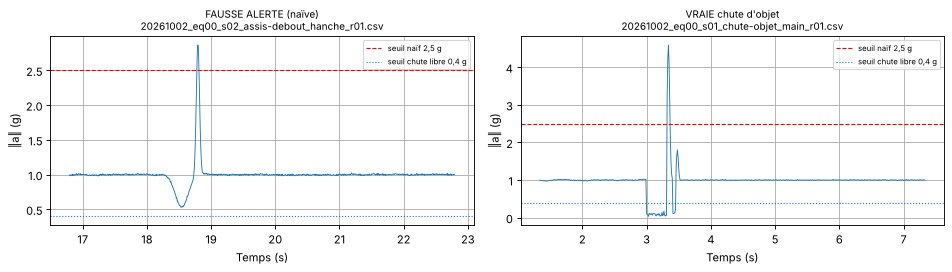

In [13]:
# Figure : fausse alerte de la règle naïve vs vraie chute d'objet
fausses = TABLE_CHUTE[TABLE_CHUTE.resultat_naive == "FP"].fichier.tolist()
chutes = TABLE_CHUTE[TABLE_CHUTE.verite_chute].fichier.tolist()
choix = ([fausses[0]] if fausses else []) + [chutes[0]]
fig, axes = plt.subplots(1, len(choix), figsize=(12, 3.5), squeeze=False)
for ax, nom in zip(axes[0], choix):
    t, acc, fs, _ = DONNEES[nom]
    n = norme(acc)
    i = int(np.argmax(n))
    z = slice(max(0, i - int(2 * fs)), min(len(n), i + int(4 * fs)))
    ax.plot(t[z], n[z], lw=0.8)
    ax.axhline(FALL_THRESHOLD_G, color="red", ls="--", lw=1, label="seuil naïf 2,5 g")
    ax.axhline(0.4, color="tab:blue", ls=":", lw=1, label="seuil chute libre 0,4 g")
    etiquette = "FAUSSE ALERTE (naïve)" if nom in fausses else "VRAIE chute d'objet"
    ax.set_title(f"{etiquette}\n{nom}", fontsize=9)
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("‖a‖ (g)")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Chute libre : 0.32 s, min 0.04 g ; impact 4.6 g ; écart-type pendant l'immobilité 0.006 g


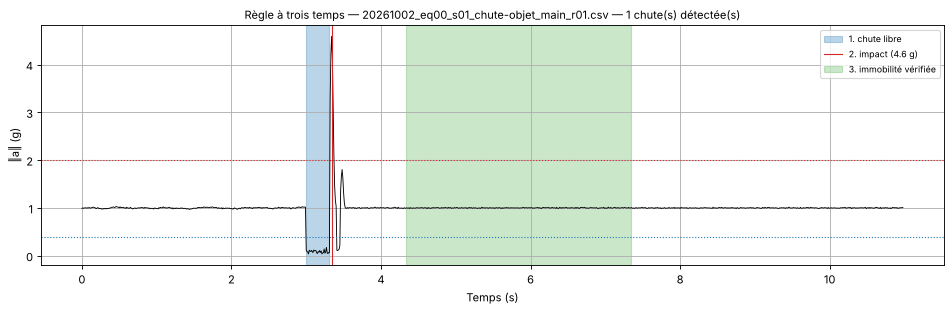

In [14]:
# Figure : la règle à trois temps sur une chute d'objet (chute libre en bleu, immobilité en vert)
NOM_CHUTE = chutes[0]
t, acc, fs, _ = DONNEES[NOM_CHUTE]
n = norme(acc)
ev = regle_trois_temps(n, fs, **REGLAGES_3T)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t, n, lw=0.8, color="black")
for e in ev:
    ax.axvspan(t[e["chute_libre"][0]], t[e["chute_libre"][1] - 1], color="tab:blue", alpha=0.3, label="1. chute libre")
    ax.axvline(t[e["impact"]], color="tab:red", lw=1, label=f"2. impact ({n[e['impact']]:.1f} g)")
    ax.axvspan(t[e["immobile"][0]], t[min(e["immobile"][1], len(t) - 1)], color="tab:green", alpha=0.25,
               label="3. immobilité vérifiée")
ax.axhline(REGLAGES_3T["seuil_cl_g"], color="tab:blue", ls=":", lw=1)
ax.axhline(REGLAGES_3T["seuil_impact_g"], color="tab:red", ls=":", lw=1)
ax.set_title(f"Règle à trois temps — {NOM_CHUTE} — {len(ev)} chute(s) détectée(s)", fontsize=10)
ax.set_xlabel("Temps (s)")
ax.set_ylabel("‖a‖ (g)")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
FIG_CHUTE = fig
plt.show()
if ev:
    e = ev[0]
    print(f"Chute libre : {(e['chute_libre'][1] - e['chute_libre'][0]) / fs:.2f} s, "
          f"min {n[e['chute_libre'][0]:e['chute_libre'][1]].min():.2f} g ; impact {n[e['impact']]:.1f} g ; "
          f"écart-type pendant l'immobilité {n[e['immobile'][0]:e['immobile'][1]].std():.3f} g")

Minimum 0.57 g (seuil chute libre 0.4 g), pic 1.92 g (seuil impact 2.0 g), écart-type 1-4 s après le choc 0.028 g (seuil 0.05 g)


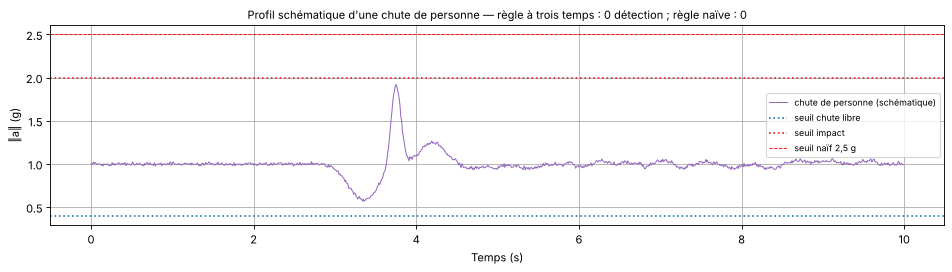

In [15]:
# Profil SCHÉMATIQUE d'une chute de personne (courbe fabriquée pour raisonner, pas une mesure)
fs_p = 100
tp = np.arange(0, 10, 1 / fs_p)
rng_p = np.random.default_rng(7)
profil = np.ones_like(tp)
profil -= 0.42 * np.exp(-0.5 * ((tp - 3.35) / 0.18) ** 2)       # perte d'appui partielle : creux vers 0,6 g
profil += 0.95 * np.exp(-0.5 * ((tp - 3.75) / 0.06) ** 2)       # choc amorti (hanche, main, meuble)
profil += 0.25 * np.exp(-0.5 * ((tp - 4.2) / 0.15) ** 2)
mouvements = np.convolve(rng_p.normal(0, 0.12, len(tp)), np.ones(25) / 25, "same")
profil += mouvements * (tp > 4.5)                                  # la personne bouge au sol
profil += rng_p.normal(0, 0.01, len(tp))
ev_p = regle_trois_temps(profil, fs_p, **REGLAGES_3T)
i_imp_p = int(np.argmax(profil))
std_p = profil[i_imp_p + fs_p: i_imp_p + 4 * fs_p].std()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(tp, profil, color="tab:purple", lw=0.9, label="chute de personne (schématique)")
ax.axhline(REGLAGES_3T["seuil_cl_g"], color="tab:blue", ls=":", label="seuil chute libre")
ax.axhline(REGLAGES_3T["seuil_impact_g"], color="tab:red", ls=":", label="seuil impact")
ax.axhline(FALL_THRESHOLD_G, color="red", ls="--", lw=0.8, label="seuil naïf 2,5 g")
ax.set_title(f"Profil schématique d'une chute de personne — règle à trois temps : {len(ev_p)} détection ; "
             f"règle naïve : {len(regle_naive(profil, fs_p))}", fontsize=10)
ax.set_xlabel("Temps (s)")
ax.set_ylabel("‖a‖ (g)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"Minimum {profil.min():.2f} g (seuil chute libre {REGLAGES_3T['seuil_cl_g']} g), pic {profil.max():.2f} g "
      f"(seuil impact {REGLAGES_3T['seuil_impact_g']} g), écart-type 1-4 s après le choc {std_p:.3f} g "
      f"(seuil {REGLAGES_3T['seuil_immobile_g']} g)")

In [16]:
# Q6 — comparaison avec le réglage « tolérant » (seuil_cl_g = 0.6, duree_immobile_s = 2.0)
TOLERANT = {**REGLAGES_3T, "seuil_cl_g": 0.6, "duree_immobile_s": 2.0}
TABLE_TOL = table_chute(TOLERANT)
m, vp, fn, fp, vn, p, r = matrice(TABLE_TOL["resultat_trois_temps"])
print("Réglage tolérant :", TOLERANT)
print(m.to_string())
print(f"Précision = {vp}/{vp + fp} = {p:.2f}   |   Rappel = {vp}/{vp + fn} = {r:.2f}")
print("Fausses alertes :", TABLE_TOL[TABLE_TOL.resultat_trois_temps == "FP"].fichier.tolist())
print(f"Profil de chute de personne avec le réglage tolérant : "
      f"{len(regle_trois_temps(profil, fs_p, **TOLERANT))} détection")

Réglage tolérant : {'seuil_cl_g': 0.6, 'duree_cl_s': 0.08, 'seuil_impact_g': 2.0, 'fenetre_impact_s': 1.0, 'seuil_immobile_g': 0.05, 'debut_immobile_s': 1.0, 'duree_immobile_s': 2.0}
              alerte  pas d'alerte
chute réelle       3             0
pas de chute       1             7
Précision = 3/4 = 0.75   |   Rappel = 3/3 = 1.00
Fausses alertes : ['20261002_eq00_s02_assis-debout_hanche_r01.csv']
Profil de chute de personne avec le réglage tolérant : 0 détection


**Q5.** Quels fichiers donnent une fausse alerte avec la règle naïve ? En une phrase : pourquoi la règle à trois temps, elle, ne sonne-t-elle pas ?

*Vos réponses :*

Avec la règle naïve, **un seul fichier** donne une fausse alerte : `20261002_eq00_s02_assis-debout_hanche_r01.csv`, où la personne **s'assoit lourdement** (pic à 2,87 g, au-dessus de 2,5 g). Résultat : précision 0,75 (3 bonnes alertes sur 4), rappel 1,00.

La règle à trois temps ne sonne pas, car il n'y a **pas de chute libre** avant ce choc : la norme ne descend qu'à 0,53 g, jamais sous 0,4 g, alors qu'un téléphone qui tombe passe vraiment près de 0 g (0,02 à 0,04 g ici, pendant 0,32 s). Elle obtient précision 1,00 et rappel 1,00.

**Q6.** Réglage « tolérant » : y a-t-il plus de fausses alertes ? La précision monte-t-elle ou baisse-t-elle ? En une phrase : pourquoi parle-t-on de compromis entre précision et rappel ?

*Vos réponses :*

**Oui**, avec le réglage tolérant (`seuil_cl_g = 0.6`, `duree_immobile_s = 2.0`), une fausse alerte apparaît : la même chute lourde sur la chaise (le creux à 0,53 g passe maintenant sous 0,6 g, puis il y a un choc et on reste assis immobile). La **précision baisse** de 1,00 à **0,75**, le rappel reste à 1,00 : on n'a rien gagné ici.

On parle de compromis car assouplir la règle pour rater moins de vraies chutes (meilleur rappel) la fait aussi sonner pour des gestes qui ressemblent à une chute (moins bonne précision), et inversement.

**Q7.** La règle à trois temps attrape toutes vos chutes de téléphone. Attrapera-t-elle la chute d'une personne âgée (cas d'usage A) : oui ou non ? Pourquoi, en une phrase ?

*Vos réponses :*

**Non.** Sur le profil schématique, la norme d'une personne qui tombe ne descend qu'à **0,57 g** : elle pivote et se rattrape, il n'y a pas de vraie chute libre sous 0,4 g. Le choc est amorti (**1,92 g**, sous le seuil de 2 g). Enfin, la personne bouge au sol (écart-type de 0,028 g, ici sous le seuil, mais une personne qui se débat le dépasserait). La règle échoue dès sa première condition : **0 détection**, même avec le réglage tolérant, et la règle naïve rate aussi. Pour le cas d'usage A, il faut des données de chutes humaines et un modèle appris (module 4).

## Étape 5 — Livrable

✏️ **À vous** : 3 lignes de conclusion (pas, chute, limite), puis exécutez la dernière cellule. Elle écrit `detections_chute.csv`, `comptage_pas.csv`, `conclusion.md` et les 3 figures dans `analyses/m2_tp2/`, et prépare `m2_tp2_eqNN.zip`.

In [17]:
#@title ✏️ À vous : 3 lignes de conclusion (pas, chute, limite)
CONCLUSION = [
    "Pas : avec un passe-bande 0,5-3 Hz et un seuil de 0,10 g, le compte est exact sur les 2 marches (50/50 et 48/48 pas, "
    "cadence 104-109 pas/min) ; un seuil de 0,3 g en fait rater 2 sur 3 (14 et 17 pas), et 16 faux pas apparaissent hors marche "
    "(assis-debout, s'allonger, chutes) : il faudrait ne compter que des séries de pas réguliers.",
    "Chute : la règle naïve (> 2,5 g) attrape les 3 chutes de téléphone mais sonne aussi pour un « s'asseoir lourdement » "
    "(précision 0,75, rappel 1,00) ; la règle à trois temps (chute libre < 0,4 g, choc > 2 g, immobilité) n'a aucune fausse "
    "alerte (précision 1,00, rappel 1,00), mais le réglage tolérant fait retomber la précision à 0,75.",
    "Limite : résultats obtenus sur le jeu de secours SYNTHÉTIQUE (aucun fichier phyphox de l'équipe dans le repo), sur 11 "
    "fichiers et 3 chutes d'objet ; une personne âgée ne tombe pas comme un téléphone (pas de chute libre, choc amorti), "
    "la règle à trois temps rate le profil schématique : il faudra des données de chutes humaines et un modèle appris (module 4).",
]

In [18]:
# ===== Écriture du livrable : exécutez sans modifier =====
(SORTIE / "figures").mkdir(parents=True, exist_ok=True)
TABLE_CHUTE.to_csv(SORTIE / "detections_chute.csv", index=False)
TABLE_PAS.to_csv(SORTIE / "comptage_pas.csv", index=False)
FIG_APERCU.savefig(SORTIE / "figures" / "apercu_normes.png", dpi=110, bbox_inches="tight")
FIG_PAS.savefig(SORTIE / "figures" / "pas_detectes.png", dpi=110, bbox_inches="tight")
FIG_CHUTE.savefig(SORTIE / "figures" / "chute_trois_temps.png", dpi=110, bbox_inches="tight")
contenu = (
    f"# TP M2-2 — Conclusion de l'équipe {EQUIPE[2:]}\n\n"
    + "\n".join(f"{i}. {ligne}" for i, ligne in enumerate(CONCLUSION, 1))
    + f"\n\n## Paramètres retenus\n\n"
    f"- Source des données : {SOURCE}\n"
    f"- Pas : passe-bande Butterworth ordre 2 {f_bas}-{f_haut} Hz (filtfilt), find_peaks hauteur {hauteur_g} g, "
    f"distance {distance_s} s\n"
    f"- Règle naïve : ‖a‖ > {FALL_THRESHOLD_G} g, 1 alerte / 10 s\n"
    f"- Règle à trois temps : chute libre < {REGLAGES_3T['seuil_cl_g']} g pendant ≥ {REGLAGES_3T['duree_cl_s']} s, "
    f"impact > {REGLAGES_3T['seuil_impact_g']} g dans les {REGLAGES_3T['fenetre_impact_s']} s, "
    f"écart-type < {REGLAGES_3T['seuil_immobile_g']} g de {REGLAGES_3T['debut_immobile_s']} à "
    f"{REGLAGES_3T['debut_immobile_s'] + REGLAGES_3T['duree_immobile_s']} s après le choc\n\n"
    f"## Scores\n\n```\n{SCORES.to_string()}\n```\n"
)
(SORTIE / "conclusion.md").write_text(contenu, encoding="utf-8")
archive = RACINE / f"m2_tp2_{EQUIPE}.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SORTIE.rglob("*")):
        if p.is_file():
            z.write(p, p.relative_to(SORTIE.parent))
print("Fichiers écrits :")
for p in sorted(SORTIE.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(RACINE))
print("Archive :", archive.name, "(à ne pas committer)")
try:
    from google.colab import files  # type: ignore
    files.download(str(archive))
except ImportError:
    pass

Fichiers écrits :
   analyses/m2_tp2/comptage_pas.csv
   analyses/m2_tp2/conclusion.md
   analyses/m2_tp2/detections_chute.csv
   analyses/m2_tp2/figures/apercu_normes.png
   analyses/m2_tp2/figures/chute_trois_temps.png
   analyses/m2_tp2/figures/pas_detectes.png
Archive : m2_tp2_eq05.zip (à ne pas committer)


## Bonus — Le lecteur accepte-t-il tous les formats d'export ?

On réécrit un même enregistrement sous plusieurs formats (séparateur `;` et virgule décimale comme un export Excel français, unités en g, colonnes renommées) et on vérifie que le lecteur retrouve la même norme.

In [19]:
nom0 = next(iter(DONNEES))
t0_, acc0_, _, _ = DONNEES[nom0]
base = pd.DataFrame({"Time (s)": t0_, "Acceleration x (m/s^2)": acc0_[:, 0] * G,
                     "Acceleration y (m/s^2)": acc0_[:, 1] * G, "Acceleration z (m/s^2)": acc0_[:, 2] * G})
formats = {
    "phyphox CSV (virgule, point décimal, m/s²)": base.to_csv(index=False),
    "phyphox CSV Excel (point-virgule, virgule décimale)": base.to_csv(index=False, sep=";", decimal=","),
    "tabulation": base.to_csv(index=False, sep="\t"),
    "colonnes en g (time, ax, ay, az)": pd.DataFrame({"time": t0_, "ax": acc0_[:, 0], "ay": acc0_[:, 1],
                                                       "az": acc0_[:, 2]}).to_csv(index=False),
}
lignes = []
for libelle, txt in formats.items():
    t_, a_, inf = lire_phyphox(txt)
    lignes.append({"format": libelle, "separateur": repr(inf["sep"]), "decimale": inf["decimal"],
                   "unite_detectee": inf["unite"], "norme_mediane_g": round(float(np.median(norme(a_))), 3),
                   "ecart_max_vs_reference_g": float(np.abs(norme(a_) - norme(acc0_)).max())})
afficher(pd.DataFrame(lignes))

                                                format separateur decimale unite_detectee  norme_mediane_g  ecart_max_vs_reference_g
0           phyphox CSV (virgule, point décimal, m/s²)        ','        .           m/s²              1.0              2.220446e-16
1  phyphox CSV Excel (point-virgule, virgule décimale)        ';'        ,           m/s²              1.0              2.220446e-16
2                                           tabulation       '\t'        .           m/s²              1.0              2.220446e-16
3                     colonnes en g (time, ax, ay, az)        ','        .              g              1.0              2.220446e-16
